# Lesson 1.2: Range, Quartiles and the Box Plot

Find the range, quartiles, IQR and outlier fences for the lesson's ten waiting times and draw one box plot.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Waiting times and the range

The lesson's nine waiting times in minutes plus one patient who waited 90. The range is the largest minus the smallest value, so it only uses two numbers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

wait = np.array([8, 12, 15, 18, 22, 27, 31, 38, 45, 90])

print('n =', len(wait))
print('min, max =', wait.min(), wait.max())
print('range =', wait.max() - wait.min())

n = 10
min, max = 8 90
range = 82


## 2. Quartiles and IQR, by the lesson's recipe

With 10 values, split the sorted data into a lower half and an upper half of 5. Q1 and Q3 are the medians of those halves. The IQR is the width of the middle 50%.

In [2]:
lower, upper = wait[:5], wait[5:]
q1, q2, q3 = np.median(lower), np.median(wait), np.median(upper)
iqr = q3 - q1

print('Q1, median, Q3 =', q1, q2, q3)
print('IQR =', iqr)

Q1, median, Q3 = 15.0 24.5 38.0
IQR = 23.0


## 3. Fences and outliers

Tukey's rule marks anything below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR as an outlier. Flagged does not mean wrong: it means look at it.

In [3]:
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print('fences:', lower_fence, 'and', upper_fence)
print('outliers:', wait[(wait < lower_fence) | (wait > upper_fence)])

software = np.percentile(wait, [25, 75])
print('NumPy default Q1, Q3 =', software, '(a different, also valid, method)')

fences: -19.5 and 72.5
outliers: [90]
NumPy default Q1, Q3 = [15.75 36.25] (a different, also valid, method)


## 4. Draw the box plot

The box runs from Q1 to Q3 with a line at the median. Whiskers stop at the most extreme values inside the fences, and the dot at 90 is the outlier. Matplotlib uses NumPy's quartile method, so its box edges are 15.75 and 36.25.

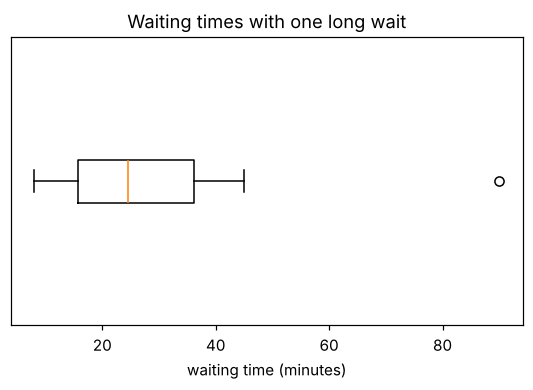

In [4]:
plt.figure(figsize=(6, 3.4))
plt.boxplot(wait, vert=False)
plt.xlabel('waiting time (minutes)')
plt.yticks([])
plt.title('Waiting times with one long wait')
plt.show()

## Try this

- Change 90 to 50 and predict whether it is still an outlier. Compute the fences, then run it.
- Remove the 90 and compare the range and the IQR. Which one changed more?

## The same idea in R, SPSS and Stata

**R**

```r
wait <- c(8, 12, 15, 18, 22, 27, 31, 38, 45, 90)
diff(range(wait))
fivenum(wait)
quantile(wait, c(0.25, 0.75))
IQR(wait)
boxplot(wait, horizontal = TRUE)
```

**SPSS** (Analyze > Descriptive Statistics > Explore)

```
DATA LIST FREE / wait.
BEGIN DATA
8  12  15  18  22  27  31  38  45  90
END DATA.
EXAMINE VARIABLES=wait
  /PLOT=BOXPLOT
  /STATISTICS=DESCRIPTIVES
  /PERCENTILES(25,50,75).
```

**Stata**

```
clear
set obs 10
generate wait = real(word("8  12  15  18  22  27  31  38  45  90", _n))
summarize wait, detail
display r(p75) - r(p25)
graph hbox wait
```